# 07 – Word2Vec, ảnh hưởng của tiền xử lý, thí nghiệm văn bản không dấu

1. **Word2Vec + LR**: thuật toán nâng cao thứ 3 (biểu diễn dày, nắm ngữ nghĩa từ).
2. **Thí nghiệm tiền xử lý** (P3.3): TF-IDF+LR với 4 mức tiền xử lý.
3. **Thí nghiệm không dấu** (P5, fairness): người gõ không dấu có bị mô hình bất lợi không, và dữ liệu Aug có giúp không?

Tất cả huấn luyện trên **A+B**, dùng tham số tốt nhất từ notebook 06 (ngram (1,2), min_df 1, C 3).

In [1]:
import sys, os
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from gensim.models import Word2Vec
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from src.data import load_sets, load_gold
from src.preprocess import normalize_text, preprocess, remove_stopwords, strip_accents

FIG, REP = "../figures", "../report"
S = load_sets()
gold, GOLD_TEMP = load_gold()
print("Tập vàng:", "TẠM nhãn sao" if GOLD_TEMP else "nhãn tay", len(gold))
AB = pd.concat([S["A"], S["B"]], ignore_index=True)
ABAug = pd.concat([S["A"], S["B"], S["Aug"]], ignore_index=True)
A_test = S["A_test"]

def tfidf_lr():
    return make_pipeline(TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=1),
                         LogisticRegression(C=3, max_iter=3000, class_weight="balanced"))

def f1(y, p):
    return round(f1_score(y, p, average="macro"), 3)

Tập vàng: nhãn tay 300


## 1. Word2Vec + Logistic Regression

Huấn luyện Word2Vec (skip-gram) trên toàn bộ văn bản train đã tách từ (A+B+Aug, khoảng 10 nghìn câu). Vector câu = trung bình vector các từ (mean pooling), nên **mất trật tự từ**: "không tốt" và "tốt không" giống nhau.

In [2]:
corpus = [s.split() for s in ABAug.text_prep]
w2v = Word2Vec(corpus, vector_size=200, window=5, min_count=2, sg=1, epochs=20, seed=42, workers=1)
print("Từ vựng:", len(w2v.wv))
for w in ["tệ", "giao_hàng", "đẹp", "rẻ"]:
    if w in w2v.wv:
        print(f"{w:10s} ->", ", ".join(f"{t}({s:.2f})" for t, s in w2v.wv.most_similar(w, topn=8)))

Từ vựng: 7768
tệ         -> dở(0.59), thảm_họa(0.58), máy_tệ(0.58), tồi_tệ(0.58), kém(0.58), lòe(0.58), nhanh_tụt(0.57), tệ_cảm_ứng(0.57)
đẹp        -> xóa_phong(0.71), pin_châu(0.69), ổn_cấu_hình(0.68), camera_chất(0.68), hình_sắc(0.67), ổn_màng(0.67), nam_tính(0.66), ngon_chiến_game(0.66)
rẻ         -> hời(0.63), siêu_rẻ(0.61), tôm(0.60), mua_lẻ(0.60), xịn_sò(0.60), được_giá(0.58), trung_tầm(0.58), ví(0.57)


In [3]:
def sent_vec(texts):
    out = np.zeros((len(texts), w2v.vector_size))
    for i, s in enumerate(texts):
        vs = [w2v.wv[t] for t in s.split() if t in w2v.wv]
        if vs:
            out[i] = np.mean(vs, axis=0)
    return out

w2v_rows = []
for C in [0.1, 1, 10]:
    clf = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=3000, class_weight="balanced"))
    clf.fit(sent_vec(S["A"].text_prep.tolist() + S["B"].text_prep.tolist()), AB.label)
    w2v_rows.append({"C": C, "F1_A_dev": f1(S["A_dev"].label, clf.predict(sent_vec(S["A_dev"].text_prep))),
                     "F1_ViSD_test": f1(A_test.label, clf.predict(sent_vec(A_test.text_prep))),
                     "F1_gold": f1(gold.label, clf.predict(sent_vec(gold.text_prep)))})
w2v_res = pd.DataFrame(w2v_rows)
w2v_res.to_csv(f"{REP}/word2vec_results.csv", index=False)
print("Chọn C theo F1_A_dev (không theo tập vàng):")
w2v_res

Chọn C theo F1_A_dev (không theo tập vàng):


,C,F1_A_dev,F1_ViSD_test,F1_gold
0,0.1,0.632,0.631,0.622
1,1.0,0.635,0.629,0.620
2,10.0,0.635,0.628,0.617


**Nhận xét.** Vector gần nhau phản ánh ngữ cảnh, không bảo đảm cùng cực tính. Lấy trung bình mất thứ tự/phạm vi phủ định. C=1 chọn theo ViSD4SA dev (F1-macro 0,635, bằng C=10; hòa thì chọn C nhỏ hơn, điều chuẩn mạnh hơn), đạt 0,629 ViSD4SA test và 0,620 vàng Shopee (thăm dò). Không kết luận Word2Vec luôn kém TF-IDF từ một cấu hình.

## 2. Ảnh hưởng của tiền xử lý

| Biến thể | Văn bản đưa vào TF-IDF |
|---|---|
| (1) Thô | văn bản gốc, chỉ viết thường |
| (2) Chuẩn hóa | NFC, viết thường, emoji → chữ, teencode, gộp ký tự lặp |
| (3) + tách từ | (2) + underthesea `word_tokenize` (= cột `text_prep`) |
| (4) + bỏ stopword | (3) + bỏ stopword, **giữ từ phủ định** |

In [4]:
def variants(df):
    return {"(1) Thô": df.text_raw.str.lower(),
            "(2) Chuẩn hóa": df.text_raw.map(normalize_text),
            "(3) + Tách từ": df.text_prep,
            "(4) + Bỏ stopword (giữ phủ định)": df.text_prep.map(remove_stopwords)}

V_tr, V_test, V_gold = variants(AB), variants(A_test), variants(gold)
pre_rows = []
for k in V_tr:
    m = tfidf_lr().fit(V_tr[k], AB.label)
    pre_rows.append({"Biến thể": k, "Số từ vựng": len(m[0].vocabulary_),
                     "F1_ViSD_test": f1(A_test.label, m.predict(V_test[k])),
                     "F1_gold": f1(gold.label, m.predict(V_gold[k]))})
pre_res = pd.DataFrame(pre_rows)
pre_res.to_csv(f"{REP}/preprocess_ablation.csv", index=False)
pre_res

,Biến thể,Số từ vựng,F1_ViSD_test,F1_gold
0,(1) Thô,102231,0.713,0.608
1,(2) Chuẩn hóa,97965,0.713,0.637
2,(3) + Tách từ,110475,0.720,0.619
3,(4) + Bỏ stopword (giữ phủ định),104323,0.727,0.591


**Nhận xét.** Theo bảng trên, F1-macro ViSD4SA test lần lượt là 0,713 (thô), 0,713 (chuẩn hóa), 0,720 (thêm tách từ) và 0,727 (thêm bỏ stopword). Trên vàng Shopee: 0,608; 0,637; 0,619; 0,591. Ablation này dùng cấu hình riêng của notebook 07, không phải kết quả sau tuning notebook 06. Tiền xử lý không giúp đồng đều giữa hai miền; không dùng điểm vàng/test để chọn lại pipeline. Tập vàng chỉ một người gán nên còn hạn chế về độ tin cậy.

## 3. Văn bản không dấu

Bỏ dấu toàn bộ tập vàng (và ViSD4SA test) rồi tiền xử lý lại. So mô hình huấn luyện trên **A+B** (gần như toàn bộ có dấu) và **A+B+Aug** (có thêm 1.205 câu không dấu).

In [5]:
def unaccent_prep(texts):
    return [preprocess(strip_accents(t)) for t in texts]

gold_ua = unaccent_prep(gold.text_raw)
test_ua = unaccent_prep(A_test.text_raw)
print("Ví dụ:", gold.text_raw.iloc[3][:80], "->", gold_ua[3][:80])

ua_rows = []
for cfg, d in [("A+B", AB), ("A+B+Aug", ABAug)]:
    m = tfidf_lr().fit(d.text_prep, d.label)
    ua_rows.append({"Train": cfg,
                    "ViSD test có dấu": f1(A_test.label, m.predict(A_test.text_prep)),
                    "ViSD test không dấu": f1(A_test.label, m.predict(test_ua)),
                    "Vàng có dấu": f1(gold.label, m.predict(gold.text_prep)),
                    "Vàng không dấu": f1(gold.label, m.predict(gold_ua))})
ua_res = pd.DataFrame(ua_rows)
ua_res.to_csv(f"{REP}/unaccent_results.csv", index=False)
ua_res

Ví dụ: Lần đầu mua hàng shopee bức xúc như này. Tính mk rất dễ đọc đáng giá của m.n thấ -> lan dau mua hang shopee buc xuc nhu_nay . tinh mình rat de doc dang_gia cua m . 


,Train,ViSD test có dấu,ViSD test không dấu,Vàng có dấu,Vàng không dấu
0,A+B,0.72,0.472,0.619,0.447
1,A+B+Aug,0.72,0.465,0.629,0.537


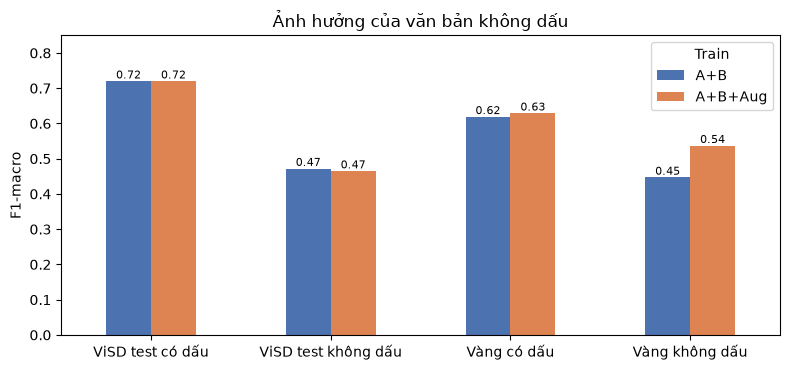

In [6]:
ax = ua_res.set_index("Train").T.plot.bar(figsize=(8, 3.8), rot=0, color=["#4C72B0", "#DD8452"])
ax.set(ylabel="F1-macro", title="Ảnh hưởng của văn bản không dấu", ylim=(0, 0.85))
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/unaccent.png", bbox_inches="tight"); plt.show()

**Nhận xét.** Ở thí nghiệm LR notebook 07, bỏ dấu làm F1-macro giảm từ 0,720 xuống 0,472 trên ViSD4SA test, từ 0,619 xuống 0,447 trên vàng. Aug nâng F1 vàng không dấu lên 0,537 nhưng không giúp ViSD4SA không dấu (0,465). Aug/vàng chỉ là thăm dò. Không gán tình trạng gõ không dấu cho tuổi, thiết bị hay nhóm xã hội vì dữ liệu không có các biến đó; cần văn bản không dấu có nguồn rõ và mẫu đánh giá độc lập.